<a href="https://colab.research.google.com/github/tanvi118/AISR_LAB/blob/main/Robotics_Exp_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tanvi Vitankar, 500120658, exp-1

1A. Time and Frequency Domain

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Sampling parameters
fs = 1000
t = np.arange(0, 1, 1/fs)

In [3]:
# Signal
f1 = 50
f2 = 120

signal = np.sin(2*np.pi*f1*t) + 0.5*np.sin(2*np.pi*f2*t)

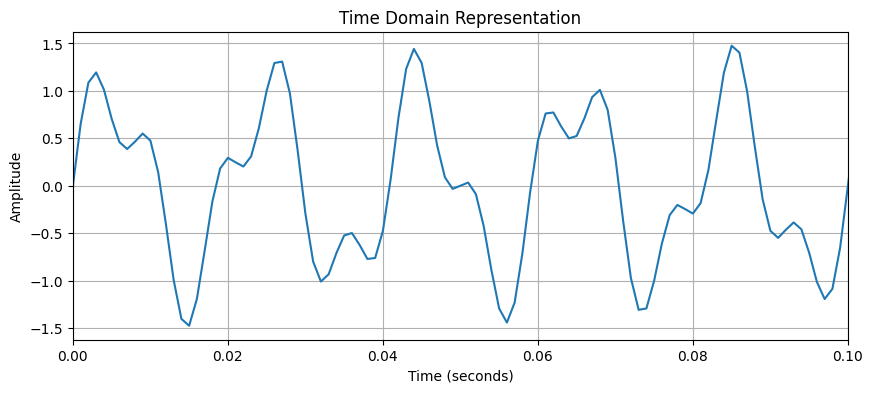

In [4]:
# Time domain
plt.figure(figsize=(10, 4))
plt.plot(t, signal)
plt.xlim(0, 0.1)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Time Domain Representation")
plt.grid()
plt.show()

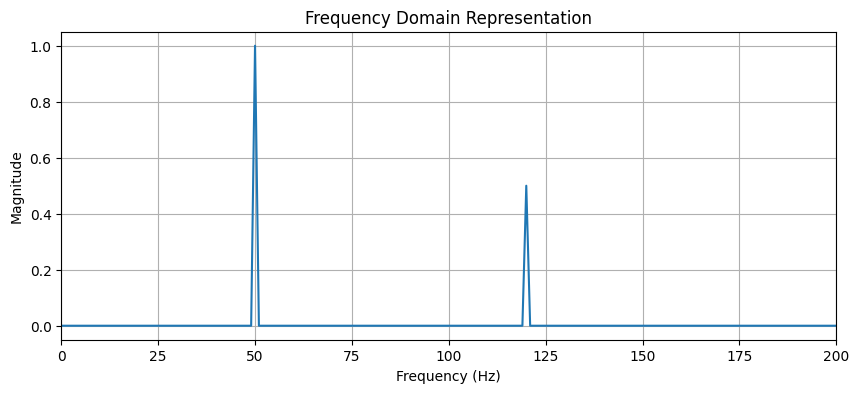

In [5]:

# Frequency domain using FFT
fft_values = np.fft.fft(signal)
frequencies = np.fft.fftfreq(len(signal), 1/fs)

positive = frequencies >= 0

plt.figure(figsize=(10, 4))
plt.plot(frequencies[positive],
         np.abs(fft_values[positive]) * 2 / len(signal))

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency Domain Representation")
plt.xlim(0, 200)
plt.grid()
plt.show()

1B. Pendulum Simulation

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

g = 9.81
L = 1.0

In [7]:
# Pendulum differential equations
def pendulum(t, y):
    theta, omega = y

    dtheta = omega
    domega = -(g/L) * np.sin(theta)

    return [dtheta, domega]

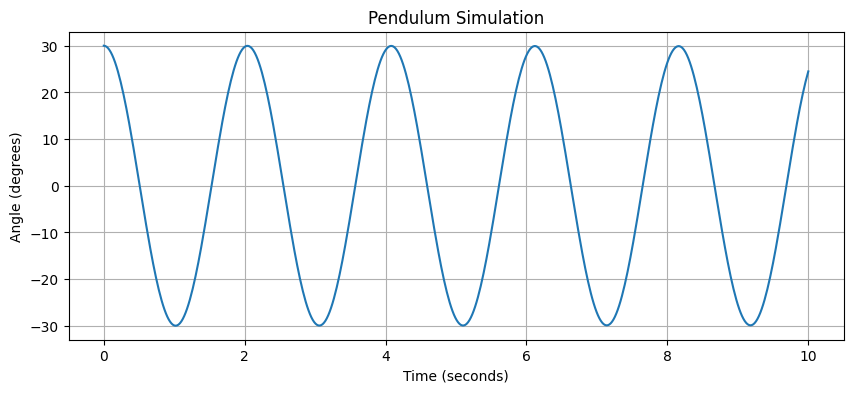

In [8]:
# Initial conditions
theta0 = np.radians(30)
omega0 = 0

t_span = (0, 10)
t_eval = np.linspace(0, 10, 500)

solution = solve_ivp(
    pendulum,
    t_span,
    [theta0, omega0],
    t_eval=t_eval
)

plt.figure(figsize=(10, 4))

plt.plot(
    solution.t,
    np.degrees(solution.y[0])
)

plt.xlabel("Time (seconds)")
plt.ylabel("Angle (degrees)")
plt.title("Pendulum Simulation")
plt.grid()
plt.show()